# Component 4 — Novelty: scBERT-Lite (gene-subset input) + attention-pooling head

Runs in a **second** Colab GPU session (L4); it only reads the data and scBERT's saved splits and writes to `scBERT_run/novelty/`.

| Config | Genes | Head | Loss |
|---|---|---|---|
| `lite2000_conv` | top 2,000 HVGs (chosen on training cells only) | repo's conv + flatten head | cross-entropy |
| `lite2000_pool` | top 2,000 HVGs | **attention pooling** | cross-entropy |

Same pretrained weights, same fit/val/test cells as Components 2–3, so every number compares 1:1.

**C (binning ablation)** is the cell after the experiments: logistic regression and MLP on scBERT's integer 0–5 tokens vs continuous values (CPU only).

In [ ]:
import os, json, glob
from google.colab import drive
drive.mount('/content/drive')
WORK, CODE = '/content/drive/MyDrive/scBERT_run', '/content'
DATA, RES, NOV = f'{WORK}/data', f'{WORK}/results', f'{WORK}/novelty'
BENCH = f'{WORK}/benchmarks'
os.makedirs(NOV, exist_ok=True); os.chdir(CODE)
REPO, CKPT = f'{CODE}/scBERT', f'{WORK}/panglao_pretrain.pth'
DATASETS = {'synthetic_holdout': f'{DATA}/synthetic_scbert.h5ad',
            'baron_holdout':     f'{DATA}/baron_scbert.h5ad',
            'zheng_ref10':       f'{DATA}/zheng68k_scbert.h5ad'}
!pip -q install local-attention einops scanpy anndata
if not os.path.exists(REPO):
    !git clone -q https://github.com/TencentAILabHealthcare/scBERT.git {REPO}
!nvidia-smi --query-gpu=name,memory.total --format=csv
for k, v in DATASETS.items():
    print(f'{k:18s} data {"OK" if os.path.exists(v) else "MISSING"}  split '
          f'{"OK" if os.path.exists(f"{RES}/{k}/fold0/split.npz") else "not yet"}')
print('checkpoint', 'OK' if os.path.exists(CKPT) else 'MISSING')

Mounted at /content/drive
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
name, memory.total [MiB]
NVIDIA L4, 23034 MiB
synthetic_holdout  data OK  split OK
baron_holdout      data OK  split OK
zheng_ref10        data OK  split OK
checkpoint OK


In [ ]:
%%writefile scbert_lite.py
import os, sys, json, time, argparse, random
import numpy as np, pandas as pd, scanpy as sc, anndata as ad, torch
from torch import nn
from scipy import sparse
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report)

p = argparse.ArgumentParser()
p.add_argument('--data', required=True); p.add_argument('--ckpt', required=True)
p.add_argument('--repo', default='/content/scBERT'); p.add_argument('--out', required=True)
p.add_argument('--split_from', required=True, help="scBERT's split.npz (fit/val/test indices)")
p.add_argument('--n_genes', type=int, default=2000, help='0 = all 16,906 genes')
p.add_argument('--head', choices=['conv', 'pool'], default='conv')
p.add_argument('--class_weight', action='store_true', help='inverse-frequency (sqrt) class weights')
p.add_argument('--epochs', type=int, default=10); p.add_argument('--patience', type=int, default=3)
p.add_argument('--batch_size', type=int, default=8); p.add_argument('--grad_acc', type=int, default=4)
p.add_argument('--lr', type=float, default=1e-4); p.add_argument('--warmup_frac', type=float, default=0.05)
p.add_argument('--eval_bs', type=int, default=32); p.add_argument('--bin_num', type=int, default=5)
p.add_argument('--seed', type=int, default=2021); p.add_argument('--amp', action='store_true')
p.add_argument('--max_hours', type=float, default=0); p.add_argument('--workers', type=int, default=2)
args = p.parse_args()

CLASS = args.bin_num + 2; N_ALL = 16906
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs(args.out, exist_ok=True)
random.seed(args.seed); np.random.seed(args.seed); torch.manual_seed(args.seed); torch.cuda.manual_seed_all(args.seed)

sys.path.insert(0, args.repo)
import performer_pytorch.performer_pytorch as pp
def _g2v_init(self, dim, max_seq_len):
    nn.Module.__init__(self); self.emb = nn.Embedding(max_seq_len, dim); self.emb.weight.requires_grad_(False)
pp.Gene2VecPositionalEmbedding.__init__ = _g2v_init
def _orth_chunk(cols, device=None):
    q, _ = torch.linalg.qr(torch.randn((cols, cols)), mode='reduced'); return q.t().to(device)
pp.orthogonal_matrix_chunk = _orth_chunk
from performer_pytorch import PerformerLM

ck = torch.load(args.ckpt, map_location='cpu', weights_only=True)
PRE = {(k[7:] if k.startswith('module.') else k): v for k, v in ck['model_state_dict'].items()}
A = sc.read_h5ad(args.data)
assert A.shape[1] == N_ALL
X = (A.X.tocsr() if sparse.issparse(A.X) else sparse.csr_matrix(A.X)).astype(np.float32)
names, y = np.unique(np.asarray(A.obs['celltype']).astype(str), return_inverse=True)
n_cls = len(names)
s = np.load(args.split_from); fit, val, test = s['fit'], s['val'], s['test']

if args.n_genes and args.n_genes < N_ALL:
    sub = ad.AnnData(X=X[fit].copy()); sub.var_names = A.var_names
    try:
        sub.uns['log1p'] = {'base': 2}
        sc.pp.highly_variable_genes(sub, n_top_genes=args.n_genes, flavor='seurat')
        sel = np.where(sub.var['highly_variable'].values)[0]
    except Exception as e:
        print('HVG selection fell back to variance ranking:', e)
        xf = X[fit]; var = np.asarray(xf.multiply(xf).mean(0)).ravel() - np.asarray(xf.mean(0)).ravel() ** 2
        sel = np.sort(np.argsort(var)[-args.n_genes:])
else:
    sel = np.arange(N_ALL)
sel = np.sort(sel); n_genes = len(sel); SEQ = n_genes + 1
Xs = X[:, sel].tocsr()
print(f'{A.n_obs} cells, {n_cls} types | genes used: {n_genes} | fit={len(fit)} val={len(val)} test={len(test)} | head={args.head}')
np.save(os.path.join(args.out, 'genes_used.npy'), np.asarray(A.var_names[sel]))

class Conv(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 1, (1, 200)); self.fc1 = nn.Linear(SEQ, 512); self.fc2 = nn.Linear(512, 128)
        self.fc3 = nn.Linear(128, n); self.act = nn.ReLU()
    def forward(self, x):
        x = self.act(self.conv1(x[:, None])).view(x.shape[0], -1)
        return self.fc3(self.act(self.fc2(self.act(self.fc1(x)))))

class Pool(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.score = nn.Linear(200, 1)
        self.mlp = nn.Sequential(nn.LayerNorm(200), nn.Linear(200, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, n))
    def forward(self, x):
        w = torch.softmax(self.score(x).squeeze(-1), dim=1)
        return self.mlp((w.unsqueeze(-1) * x).sum(1))

def build():
    m = PerformerLM(num_tokens=CLASS, dim=200, depth=6, max_seq_len=SEQ, heads=10, local_attn_heads=0, g2v_position_emb=True)
    sd = dict(PRE)
    g2v = sd['pos_emb.emb.weight']
    sd['pos_emb.emb.weight'] = g2v[torch.as_tensor(np.concatenate([sel, [N_ALL]]), dtype=torch.long)]
    m.load_state_dict(sd, strict=True)
    for prm in m.parameters(): prm.requires_grad = False
    for prm in m.norm.parameters(): prm.requires_grad = True
    for prm in m.performer.net.layers[-2].parameters(): prm.requires_grad = True
    m.to_out = Conv(n_cls) if args.head == 'conv' else Pool(n_cls)
    return m.to(dev)

class DS(torch.utils.data.Dataset):
    def __init__(self, idx): self.idx = np.asarray(idx)
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        r = self.idx[i]; row = Xs[r].toarray()[0]; row[row > CLASS - 2] = CLASS - 2
        return torch.cat((torch.from_numpy(row).long(), torch.tensor([0]))), int(y[r])
def loader(idx, shuffle, bs):
    return torch.utils.data.DataLoader(DS(idx), batch_size=bs, shuffle=shuffle, num_workers=args.workers, pin_memory=True)
AMP_DT = torch.bfloat16 if dev.type == 'cuda' and torch.cuda.is_bf16_supported() else torch.float16
def autocast(): return torch.autocast('cuda', dtype=AMP_DT, enabled=args.amp and dev.type == 'cuda')

@torch.no_grad()
def predict(model, idx):
    model.eval(); out = []
    for seq, _ in loader(idx, False, args.eval_bs):
        with autocast(): out.append(torch.softmax(model(seq.to(dev)).float(), -1).cpu())
    return torch.cat(out).numpy()

mf = os.path.join(args.out, 'metrics.json')
if os.path.exists(mf):
    print('already done:', mf); sys.exit(0)
model = build()
n_train = sum(p_.numel() for p_ in model.parameters() if p_.requires_grad)
n_head = sum(p_.numel() for p_ in model.to_out.parameters())
opt = torch.optim.Adam([p_ for p_ in model.parameters() if p_.requires_grad], lr=args.lr)
steps = args.epochs * int(np.ceil(np.ceil(len(fit) / args.batch_size) / args.grad_acc))
warm = max(1, int(args.warmup_frac * steps)); floor = 1e-6 / args.lr
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: floor + (1 - floor) * ((t + 1) / warm if t < warm else
                                          0.5 * (1 + np.cos(np.pi * min(1.0, (t - warm) / max(1, steps - warm))))))
if args.class_weight:
    cnt = np.bincount(y[fit], minlength=n_cls).astype(float)
    wts = 1 / np.sqrt(np.maximum(cnt, 1)); wts = wts / (wts * cnt).sum() * cnt.sum()
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(wts, dtype=torch.float32, device=dev))
else:
    loss_fn = nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler('cuda', enabled=args.amp and AMP_DT == torch.float16)
best_p = os.path.join(args.out, 'best.pt'); best, bad, log = -1, 0, []
t_start = time.time(); train_cells = 0
for ep in range(1, args.epochs + 1):
    model.train(); t0 = time.time(); tot, nb = 0.0, 0; opt.zero_grad(set_to_none=True)
    for b, (seq, lab) in enumerate(loader(fit, True, args.batch_size), 1):
        with autocast():
            loss = loss_fn(model(seq.to(dev, non_blocking=True)), lab.to(dev, non_blocking=True))
        scaler.scale(loss / args.grad_acc).backward(); tot += loss.item(); nb += 1
        if b % args.grad_acc == 0 or b * args.batch_size >= len(fit):
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
    train_cells += len(fit); t_train = time.time() - t0
    vp = predict(model, val).argmax(1); va = accuracy_score(y[val], vp); vf = f1_score(y[val], vp, average='macro')
    log.append({'epoch': ep, 'train_loss': tot / nb, 'val_acc': va, 'val_macro_f1': vf, 'minutes': (time.time() - t0) / 60})
    print(f'epoch {ep}: loss {tot / nb:.4f}  val acc {va:.4f}  val F1 {vf:.4f}  ({(time.time() - t0) / 60:.1f} min, '
          f'{t_train / len(fit):.4f} s/cell train)', flush=True)
    if va > best:
        best, bad = va, 0; torch.save(model.state_dict(), best_p)
    else:
        bad += 1
        if bad >= args.patience: print('early stopping'); break
    if args.max_hours and (time.time() - t_start) / 3600 > args.max_hours: print('time budget reached'); break
train_minutes = (time.time() - t_start) / 60

model.load_state_dict(torch.load(best_p, map_location='cpu', weights_only=True))
t0 = time.time(); probs = predict(model, test); infer_spc = (time.time() - t0) / len(test)
pred = probs.argmax(1); yt = y[test]
m = {'experiment': os.path.basename(args.out.rstrip('/')), 'n_genes': n_genes, 'head': args.head,
     'class_weight': args.class_weight, 'trainable_params': n_train, 'head_params': n_head,
     'n_fit': len(fit), 'n_val': len(val), 'n_test': len(test), 'epochs_run': len(log), 'best_val_acc': best,
     'train_minutes': train_minutes, 'train_sec_per_cell': train_minutes * 60 / max(train_cells, 1),
     'infer_sec_per_cell': infer_spc,
     'test_accuracy': accuracy_score(yt, pred),
     'test_macro_precision': precision_score(yt, pred, average='macro', zero_division=0),
     'test_macro_recall': recall_score(yt, pred, average='macro', zero_division=0),
     'test_macro_f1': f1_score(yt, pred, average='macro', zero_division=0),
     'test_weighted_f1': f1_score(yt, pred, average='weighted', zero_division=0),
     'per_class': classification_report(yt, pred, labels=range(n_cls), target_names=names, output_dict=True, zero_division=0),
     'labels': names.tolist(), 'confusion_matrix': confusion_matrix(yt, pred, labels=range(n_cls)).tolist(),
     'log': log, 'args': vars(args)}
json.dump(m, open(mf, 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
pd.DataFrame({'cell': A.obs_names[test], 'true': names[yt], 'pred': names[pred], 'confidence': probs.max(1)}).to_csv(
    os.path.join(args.out, 'test_predictions.csv'), index=False)
print(f'TEST acc {m["test_accuracy"]:.4f}  macro P {m["test_macro_precision"]:.4f}  macro R {m["test_macro_recall"]:.4f}  '
      f'macro F1 {m["test_macro_f1"]:.4f} | trainable params {n_train:,} (head {n_head:,}) | {train_minutes:.1f} min')
print(classification_report(yt, pred, labels=range(n_cls), target_names=names, digits=4, zero_division=0))

Writing scbert_lite.py


## Run the novelty experiments (rerun this cell after a disconnect; finished configs are skipped)
Each epoch prints seconds per cell, so you can see the speed-up versus full scBERT (~0.25 s/cell).

In [ ]:
CONFIGS = {'lite2000_conv':    '--n_genes 2000 --head conv',
           'lite2000_pool':    '--n_genes 2000 --head pool'}
PLAN = [('synthetic_holdout', ['lite2000_conv', 'lite2000_pool']),
        ('baron_holdout',     ['lite2000_conv', 'lite2000_pool']),
        ('zheng_ref10',       ['lite2000_conv', 'lite2000_pool'])]
for exp, cfgs in PLAN:
    split = f'{RES}/{exp}/fold0/split.npz'
    if not os.path.exists(split):
        print(f'== {exp}: split not saved yet, skipping (rerun later)'); continue
    for cfg in cfgs:
        out = f'{NOV}/{exp}/{cfg}'
        if os.path.exists(f'{out}/metrics.json'):
            print(f'== {exp} / {cfg}: done'); continue
        print(f'\n================ {exp} / {cfg} ================')
        get_ipython().system(f'python scbert_lite.py --data "{DATASETS[exp]}" --ckpt "{CKPT}" --repo "{REPO}" '
                             f'--split_from "{split}" --out "{out}" {CONFIGS[cfg]} --epochs 10 --patience 3 --amp '
                             f'--max_hours 1 2>&1 | tee -a "{out}.log"')


================ synthetic_holdout / lite2000_conv ================
tee: /content/drive/MyDrive/scBERT_run/novelty/synthetic_holdout/lite2000_conv.log: No such file or directory
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
4000 cells, 6 types | genes used: 2000 | fit=1200 val=200 test=600 | head=conv
epoch 1: loss 1.7033  val acc 0.2950  val F1 0.0759  (0.7 min, 0.0301 s/cell train)
epoch 2: loss 1.6760  val acc 0.2950  val F1 0.0759  (0.6 min, 0.0285 s/cell train)
epoch 3: loss 1.6600  val acc 0.2950  val F1 0.0759  (0.6 min, 0.0286 s/cell train)
epoch 4: loss 1.6338  val acc 0.2400  val F1 0.0692  (0.6 min, 0.0286 s/cell train)
early stopping
TEST acc 0.2983  macro P 0.0497  macro R 0.1667  macro F1 0.0766 | trainable params 1,926,063 (head 1,091,663) | 2.6 min
              precision    recall  f1-score   support

     

## C — Binning ablation (CPU, ~10 min): do baselines lose accuracy when given scBERT's integer input?

In [ ]:
import time, numpy as np, pandas as pd, scanpy as sc, torch
from torch import nn
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report)
torch.set_num_threads(os.cpu_count())

def load(path):
    ad = sc.read_h5ad(path)
    X = ad.X.tocsr() if sparse.issparse(ad.X) else sparse.csr_matrix(ad.X)
    names, y = np.unique(np.asarray(ad.obs['celltype']).astype(str), return_inverse=True)
    return X.astype(np.float32), y, names, ad.obs_names

def metrics(yt, pred, names, extra):
    n = len(names)
    return {**extra,
            'test_accuracy': accuracy_score(yt, pred),
            'test_macro_precision': precision_score(yt, pred, average='macro', zero_division=0),
            'test_macro_recall': recall_score(yt, pred, average='macro', zero_division=0),
            'test_macro_f1': f1_score(yt, pred, average='macro', zero_division=0),
            'test_weighted_f1': f1_score(yt, pred, average='weighted', zero_division=0),
            'per_class': classification_report(yt, pred, labels=range(n), target_names=names,
                                               output_dict=True, zero_division=0),
            'labels': names.tolist(),
            'confusion_matrix': confusion_matrix(yt, pred, labels=range(n)).tolist()}

def run_logreg(X, y, fit, val, test):
    best = None
    for C in [0.01, 0.1, 1.0]:
        t0 = time.time()
        clf = LogisticRegression(C=C, max_iter=1000, tol=1e-4)
        clf.fit(X[fit], y[fit])
        va = accuracy_score(y[val], clf.predict(X[val]))
        print(f'    logreg C={C:<5} val acc {va:.4f}  ({time.time() - t0:.0f}s)')
        if best is None or va > best[0]:
            best = (va, C, clf)
    va, C, clf = best
    return clf.predict(X[test]), {'best_val_acc': va, 'C': C}

def run_mlp(X, y, fit, val, test, n_cls, seed=2021, epochs=60, patience=6, bs=128):
    torch.manual_seed(seed); np.random.seed(seed)
    net = nn.Sequential(nn.Linear(X.shape[1], 256), nn.ReLU(), nn.Dropout(0.3),
                        nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, n_cls))
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    lossf = nn.CrossEntropyLoss()
    dense = lambda idx: torch.from_numpy(X[idx].toarray())
    def predict(idx):
        net.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(idx), 1024):
                out.append(net(dense(idx[i:i + 1024])).argmax(1).numpy())
        return np.concatenate(out)
    best_acc, best_state, bad, log = -1, None, 0, []
    for ep in range(1, epochs + 1):
        net.train(); order = np.random.permutation(fit); tot = 0.0
        for i in range(0, len(order), bs):
            b = order[i:i + bs]
            loss = lossf(net(dense(b)), torch.from_numpy(y[b]).long())
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        va = accuracy_score(y[val], predict(val)); log.append({'epoch': ep, 'train_loss': tot / len(fit), 'val_acc': va})
        if va > best_acc:
            best_acc, bad = va, 0; best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    net.load_state_dict(best_state)
    print(f'    mlp: {len(log)} epochs, best val acc {best_acc:.4f}')
    return predict(test), {'best_val_acc': best_acc, 'epochs_run': len(log), 'log': log}

_js = lambda o: o.item() if hasattr(o, 'item') else str(o)
cache, rows = {}, []
for name in ['synthetic_holdout', 'baron_holdout', 'zheng_ref10']:
    split_p = f'{RES}/{name}/fold0/split.npz'
    if not os.path.exists(split_p):
        print(f'== {name}: split not ready, skipping'); continue
    path = DATASETS[name]
    if path not in cache: cache[path] = load(path)
    X, y, names, cells = cache[path]
    Xb = X.copy(); Xb.data = np.floor(np.minimum(Xb.data, 5)); Xb.eliminate_zeros()
    s = np.load(split_p); fit, val, test = s['fit'], s['val'], s['test']
    print(f'\n== {name}: {X.nnz:,} nonzero values -> {Xb.nnz:,} after binning ({1 - Xb.nnz / X.nnz:.0%} become 0)')
    for model in ['logreg', 'mlp']:
        res = {}
        for kind, Xk in [('', X), ('_binned', Xb)]:
            out = f'{BENCH}/{name}/{model}{kind}'
            if not os.path.exists(f'{out}/metrics.json'):
                os.makedirs(out, exist_ok=True); t0 = time.time()
                pred, extra = run_logreg(Xk, y, fit, val, test) if model == 'logreg' else run_mlp(Xk, y, fit, val, test, len(names))
                m = metrics(y[test], pred, names, {'model': model + kind, 'experiment': name, 'n_fit': len(fit),
                                                   'n_val': len(val), 'n_test': len(test),
                                                   'train_minutes': (time.time() - t0) / 60, **extra})
                json.dump(m, open(f'{out}/metrics.json', 'w'), indent=1, default=_js)
            res[kind] = json.load(open(f'{out}/metrics.json'))
        rows.append({'experiment': name, 'model': model,
                     'acc continuous': res['']['test_accuracy'], 'acc binned': res['_binned']['test_accuracy'],
                     'Δ acc': res['_binned']['test_accuracy'] - res['']['test_accuracy'],
                     'F1 continuous': res['']['test_macro_f1'], 'F1 binned': res['_binned']['test_macro_f1'],
                     'Δ F1': res['_binned']['test_macro_f1'] - res['']['test_macro_f1']})
abl = pd.DataFrame(rows); abl.to_csv(f'{NOV}/binning_ablation.csv', index=False)
print('\n================ BINNING ABLATION (same test cells) ================')
print(abl.round(4).to_string(index=False))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (



== synthetic_holdout: 8,826,059 nonzero values -> 8,739,226 after binning (1% become 0)
    logreg C=0.01  val acc 0.8650  (27s)
    logreg C=0.1   val acc 0.8700  (9s)
    logreg C=1.0   val acc 0.8750  (7s)
    mlp: 15 epochs, best val acc 0.7550

== baron_holdout: 15,156,082 nonzero values -> 14,066,061 after binning (7% become 0)
    logreg C=0.01  val acc 0.9720  (23s)
    logreg C=0.1   val acc 0.9780  (19s)
    logreg C=1.0   val acc 0.9820  (13s)
    mlp: 15 epochs, best val acc 0.9860

== zheng_ref10: 33,627,905 nonzero values -> 33,627,905 after binning (0% become 0)
    logreg C=0.01  val acc 0.6580  (54s)
    logreg C=0.1   val acc 0.6500  (54s)
    logreg C=1.0   val acc 0.6540  (41s)
    logreg C=0.01  val acc 0.6760  (47s)
    logreg C=0.1   val acc 0.6680  (46s)
    logreg C=1.0   val acc 0.6680  (37s)
    mlp: 13 epochs, best val acc 0.6820
    mlp: 9 epochs, best val acc 0.6880

================ BINNING ABLATION (same test cells) ================
       experiment  m

## Results: novelty vs full scBERT (Component 2) vs baselines (Component 3), same test cells


######## synthetic_holdout: per-class F1
        test cells  scBERT (full, paper recipe)  logreg    mlp  scBERT-lite2000_conv  scBERT-lite2000_pool
type_A         179                         0.46   0.829  0.678                  0.46                  0.46
type_B         140                         0.00   0.816  0.652                  0.00                  0.00
type_C         110                         0.00   0.991  0.914                  0.00                  0.00
type_D          82                         0.00   0.952  0.841                  0.00                  0.00
type_E          50                         0.00   0.709  0.241                  0.00                  0.00
type_F          39                         0.00   0.932  0.756                  0.00                  0.00

######## baron_holdout: per-class F1
                    test cells  scBERT (full, paper recipe)  logreg    mlp  scBERT-lite2000_conv  scBERT-lite2000_pool
beta                       505                      

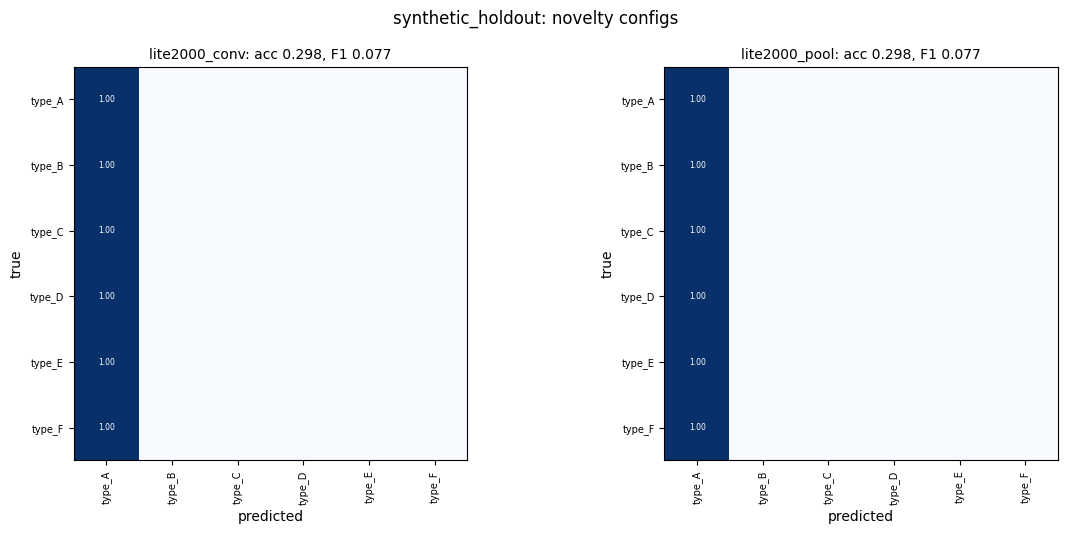

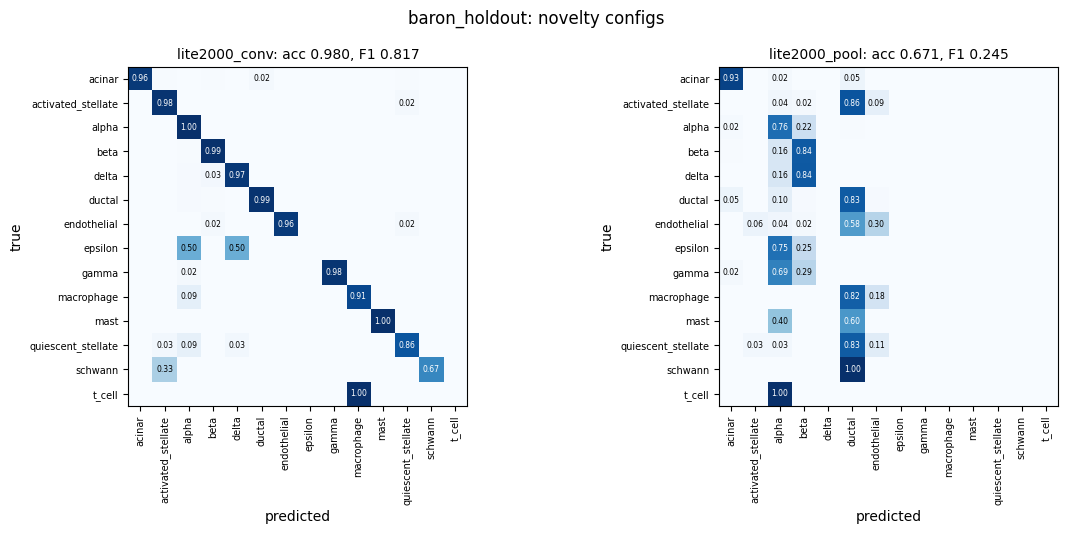

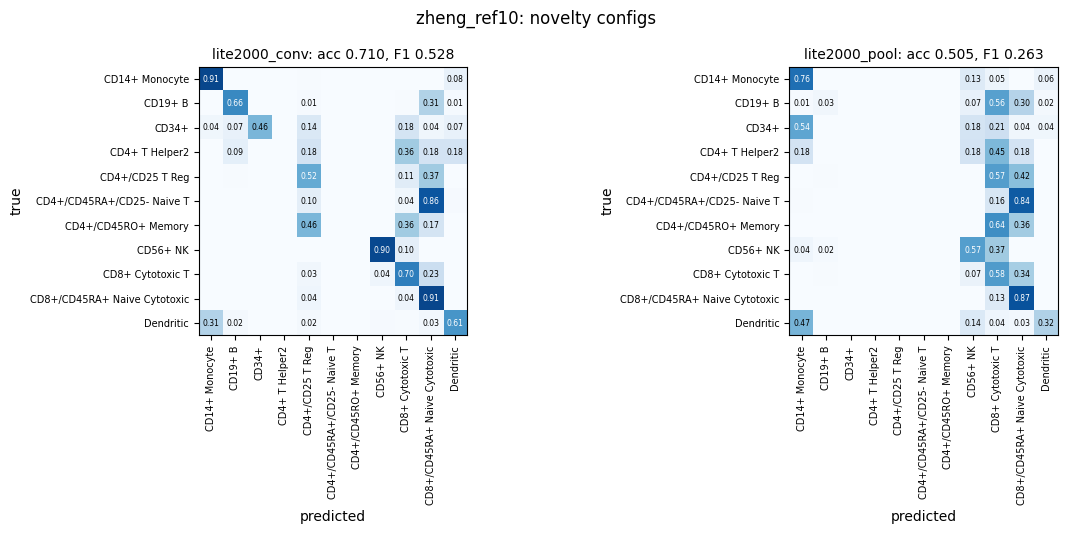

saved: /content/drive/MyDrive/scBERT_run/novelty/novelty_results.csv, *_per_class_f1.csv, *_confusion_matrices.png


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
def get(p): return json.load(open(p)) if os.path.exists(p) else None
rows = []
for exp in DATASETS:
    cands = {'scBERT (full, paper recipe)': f'{RES}/{exp}/fold0/metrics.json',
             'logreg': f'{BENCH}/{exp}/logreg/metrics.json', 'mlp': f'{BENCH}/{exp}/mlp/metrics.json',
             **{f'scBERT-{c}': f'{NOV}/{exp}/{c}/metrics.json' for c in ['lite2000_conv', 'lite2000_pool']}}
    per_class = {}
    for model, path in cands.items():
        m = get(path)
        if m is None: continue
        if model.startswith('scBERT (full'):
            minutes = sum(l.get('minutes', 0) for l in m['log']); genes, head_p = 16906, None
        else:
            minutes = m.get('train_minutes'); genes, head_p = m.get('n_genes', 16906), m.get('head_params')
        rows.append({'experiment': exp, 'model': model, 'genes': genes, 'accuracy': m['test_accuracy'],
                     'macro P': m['test_macro_precision'], 'macro R': m['test_macro_recall'],
                     'macro F1': m['test_macro_f1'], 'weighted F1': m['test_weighted_f1'],
                     'train min': minutes, 'train s/cell': m.get('train_sec_per_cell'),
                     'trainable params': m.get('trainable_params'), 'head params': head_p})
        per_class[model] = {l: m['per_class'][l]['f1-score'] for l in m['labels']}
        support = {l: int(m['per_class'][l]['support']) for l in m['labels']}
    if per_class:
        pc = pd.DataFrame(per_class); pc.insert(0, 'test cells', pd.Series(support))
        print(f'\n######## {exp}: per-class F1'); print(pc.sort_values('test cells', ascending=False).round(3).to_string())
        pc.to_csv(f'{NOV}/{exp}_per_class_f1.csv')
table = pd.DataFrame(rows); table.to_csv(f'{NOV}/novelty_results.csv', index=False)
pd.set_option('display.width', 260); pd.set_option('display.max_columns', 20)
print('\n================ NOVELTY RESULTS (test set) ================')
print(table.round(4).to_string(index=False))

for exp in DATASETS:
    ms = {c: get(f'{NOV}/{exp}/{c}/metrics.json') for c in ['lite2000_conv', 'lite2000_pool']}
    ms = {c: m for c, m in ms.items() if m}
    if not ms: continue
    fig, axs = plt.subplots(1, len(ms), figsize=(6 * len(ms), 5.4), squeeze=False)
    for ax, (c, m) in zip(axs[0], ms.items()):
        cm = np.array(m['confusion_matrix'], float); cmn = cm / cm.sum(1, keepdims=True).clip(min=1); L = m['labels']
        ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
        ax.set_xticks(range(len(L))); ax.set_xticklabels(L, rotation=90, fontsize=7); ax.set_yticks(range(len(L))); ax.set_yticklabels(L, fontsize=7)
        for i in range(len(L)):
            for j in range(len(L)):
                if cmn[i, j] >= .01: ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', fontsize=5.5, color='white' if cmn[i, j] > .5 else 'black')
        ax.set_title(f'{c}: acc {m["test_accuracy"]:.3f}, F1 {m["test_macro_f1"]:.3f}', fontsize=10); ax.set_xlabel('predicted'); ax.set_ylabel('true')
    fig.suptitle(f'{exp}: novelty configs'); fig.tight_layout(); fig.savefig(f'{NOV}/{exp}_confusion_matrices.png', dpi=200); plt.show()
print(f'saved: {NOV}/novelty_results.csv, *_per_class_f1.csv, *_confusion_matrices.png')